In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# ============================================================
# DATASET LOADED SUCCESSFULLY
# ============================================================

df = pd.read_csv(r"D:\Data scientist\Credit risk Project\data\synthetic\borrower_credit_data.csv")

print("=" * 60)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 60)

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Records:")
display(df.head())

DATASET LOADED SUCCESSFULLY

Dataset Shape:
(10000, 28)

First 5 Records:


,borrower_id,bank,age,employment_type,employment_length_years,annual_income,credit_score,loan_amount,loan_term_months,interest_rate,...,loan_purpose,monthly_income,monthly_emi,debt_to_income_ratio,loan_to_income_ratio,bank_gross_npas,bank_gross_advances,bank_gross_npa_ratio,risk_category,default_flag
0,BRW000001,STATE BANK OF INDIA,52,Business Owner,7.2,495999.0,602,1037176.0,120,9.50,...,Medical,41333.25,13420.80,0.55,2.09,76880.20,4220702.74,1.82,Medium,0
1,BRW000002,ICICI BANK LIMITED,56,Salaried,8.8,346767.0,643,2020637.0,60,13.08,...,Vehicle,28897.25,46058.49,1.79,5.83,23523.10,1359789.89,1.73,High,0
2,BRW000003,DCB BANK LIMITED,57,Salaried,7.1,710300.0,688,1144821.0,60,15.21,...,Education,59191.67,27361.57,1.18,1.61,1554.43,52047.53,2.99,Medium,0
3,BRW000004,AXIS BANK LIMITED,34,Salaried,8.1,769394.0,843,1547261.0,36,12.26,...,Education,64116.17,51583.56,1.07,2.01,13961.19,1051087.06,1.33,Low,0
4,BRW000005,CANARA BANK,47,Self-Employed,2.2,180000.0,673,569667.0,120,8.86,...,Vehicle,15000.00,7173.21,1.52,3.16,31530.03,1073331.74,2.94,Medium,0


In [3]:
# ============================================================
# 2. BASIC DATASET OVERVIEW
# ============================================================

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("\nRows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i:02d}. {column}")

print("\nDataset Info:")
df.info()

DATASET OVERVIEW

Rows: 10000
Columns: 28

Column Names:
01. borrower_id
02. bank
03. age
04. employment_type
05. employment_length_years
06. annual_income
07. credit_score
08. loan_amount
09. loan_term_months
10. interest_rate
11. existing_debt
12. existing_loans
13. previous_delinquencies
14. previous_defaults
15. credit_history_years
16. open_credit_accounts
17. dependents
18. home_ownership
19. loan_purpose
20. monthly_income
21. monthly_emi
22. debt_to_income_ratio
23. loan_to_income_ratio
24. bank_gross_npas
25. bank_gross_advances
26. bank_gross_npa_ratio
27. risk_category
28. default_flag

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 28 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   borrower_id              10000 non-null  str    
 1   bank                     10000 non-null  str    
 2   age                      10000 non-null  int64  
 3   employmen

In [4]:
# ============================================================
# 3. TARGET VARIABLE ANALYSIS
# ============================================================

print("=" * 60)
print("DEFAULT FLAG ANALYSIS")
print("=" * 60)

default_counts = df["default_flag"].value_counts().sort_index()

print("\nDefault Distribution:")
print(default_counts)

default_percentage = (
    df["default_flag"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nDefault Percentage:")
print(default_percentage)

print("\nDefault Rate:")
print(f"{df['default_flag'].mean() * 100:.2f}%")

DEFAULT FLAG ANALYSIS

Default Distribution:
default_flag
0    9300
1     700
Name: count, dtype: int64

Default Percentage:
default_flag
0    93.0
1     7.0
Name: proportion, dtype: float64

Default Rate:
7.00%


In [5]:
# ============================================================
# 4. DATA QUALITY CHECK
# ============================================================

print("=" * 60)
print("DATA QUALITY CHECK")
print("=" * 60)

print("\nMissing Values:")
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

if missing_values.sum() == 0:
    print("✓ No missing values found.")

print("\nDuplicate Rows:")
duplicates = df.duplicated().sum()
print(duplicates)

if duplicates == 0:
    print("✓ No duplicate rows found.")

print("\nUnique Borrowers:")
print(df["borrower_id"].nunique())

print("\nTarget Classes:")
print(df["default_flag"].unique())

DATA QUALITY CHECK

Missing Values:
Series([], dtype: int64)
✓ No missing values found.

Duplicate Rows:
0
✓ No duplicate rows found.

Unique Borrowers:
10000

Target Classes:
[0 1]


In [6]:
# ============================================================
# 5. NUMERICAL FEATURES - STATISTICAL SUMMARY
# ============================================================

print("=" * 60)
print("NUMERICAL FEATURE ANALYSIS")
print("=" * 60)

# Select numerical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("\nNumerical Columns:")
print(numerical_columns)

print("\nNumber of Numerical Features:")
print(len(numerical_columns))

# Statistical summary
numeric_summary = df[numerical_columns].describe().T

numeric_summary

NUMERICAL FEATURE ANALYSIS

Numerical Columns:
['age', 'employment_length_years', 'annual_income', 'credit_score', 'loan_amount', 'loan_term_months', 'interest_rate', 'existing_debt', 'existing_loans', 'previous_delinquencies', 'previous_defaults', 'credit_history_years', 'open_credit_accounts', 'dependents', 'monthly_income', 'monthly_emi', 'debt_to_income_ratio', 'loan_to_income_ratio', 'bank_gross_npas', 'bank_gross_advances', 'bank_gross_npa_ratio', 'default_flag']

Number of Numerical Features:
22


,count,mean,std,min,25%,50%,75%,max
age,10000.0,4.039900e+01,1.151196e+01,21.00,30.0000,40.000,5.000000e+01,60.00
employment_length_years,10000.0,7.481010e+00,4.809305e+00,0.50,3.9000,6.400,9.900000e+00,30.00
annual_income,10000.0,6.950872e+05,4.026805e+05,180000.00,416251.2500,603521.500,8.662820e+05,4237196.00
credit_score,10000.0,7.088865e+02,6.992796e+01,457.00,662.0000,709.000,7.550000e+02,900.00
loan_amount,10000.0,8.873570e+05,6.788738e+05,50000.00,434931.7500,695501.500,1.123676e+06,5000000.00
loan_term_months,10000.0,6.090120e+01,3.075541e+01,12.00,36.0000,60.000,8.400000e+01,120.00
interest_rate,10000.0,1.153934e+01,2.473236e+00,6.00,9.8400,11.490,1.322000e+01,20.00
existing_debt,10000.0,5.397313e+05,4.578960e+05,9268.00,215550.0000,419376.000,7.298598e+05,4587828.00
existing_loans,10000.0,1.484200e+00,1.217333e+00,0.00,1.0000,1.000,2.000000e+00,8.00
previous_delinquencies,10000.0,3.607000e-01,6.025212e-01,0.00,0.0000,0.000,1.000000e+00,4.00


In [7]:
# ============================================================
# 6. CATEGORICAL FEATURES ANALYSIS
# ============================================================

print("=" * 60)
print("CATEGORICAL FEATURE ANALYSIS")
print("=" * 60)

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nCategorical Columns:")
print(categorical_columns)

print("\nNumber of Categorical Features:")
print(len(categorical_columns))

for column in categorical_columns:

    print("\n" + "-" * 60)
    print(f"{column.upper()}")
    print("-" * 60)

    print(df[column].value_counts())

CATEGORICAL FEATURE ANALYSIS

Categorical Columns:
['borrower_id', 'bank', 'employment_type', 'home_ownership', 'loan_purpose', 'risk_category']

Number of Categorical Features:
6

------------------------------------------------------------
BORROWER_ID
------------------------------------------------------------
borrower_id
BRW000001    1
BRW000002    1
BRW000003    1
BRW000004    1
BRW000005    1
            ..
BRW009996    1
BRW009997    1
BRW009998    1
BRW009999    1
BRW010000    1
Name: count, Length: 10000, dtype: int64

------------------------------------------------------------
BANK
------------------------------------------------------------
bank
STATE BANK OF INDIA        1601
HDFC BANK LTD.             1140
ICICI BANK LIMITED         1035
AXIS BANK LIMITED           872
BANK OF BARODA              693
CANARA BANK                 670
PUNJAB NATIONAL BANK        588
UNION BANK OF INDIA         493
BANK OF INDIA               413
INDIAN BANK                 407
BANK OF MAHARA

C:\Users\HP\AppData\Local\Temp\ipykernel_13920\1621602519.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [8]:
# ============================================================
# 7. CREDIT SCORE VS DEFAULT
# ============================================================

print("=" * 60)
print("CREDIT SCORE VS DEFAULT")
print("=" * 60)

credit_score_default = (
    df.groupby("default_flag")["credit_score"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

credit_score_default

CREDIT SCORE VS DEFAULT


,count,mean,median,min,max
default_flag,,,,,
0,9300,712.82,712.0,457,900
1,700,656.67,660.0,463,842


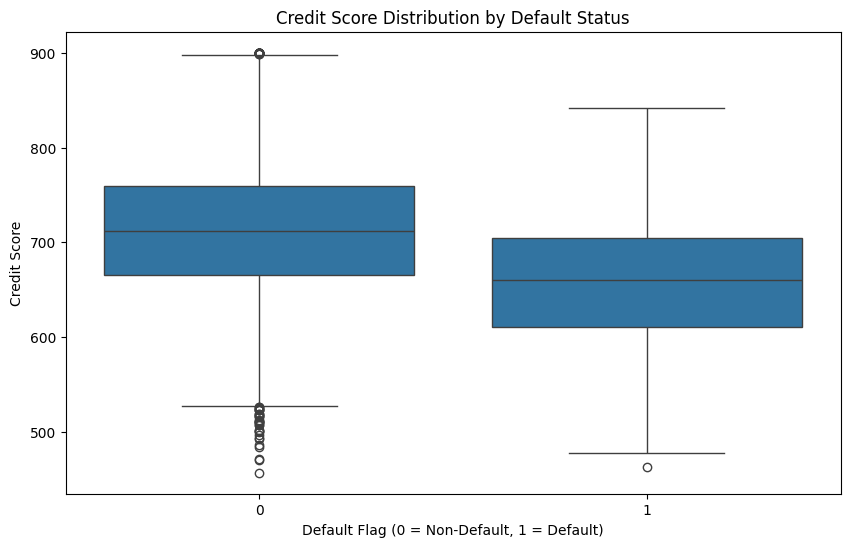

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="default_flag",
    y="credit_score"
)

plt.title("Credit Score Distribution by Default Status")
plt.xlabel("Default Flag (0 = Non-Default, 1 = Default)")
plt.ylabel("Credit Score")

plt.show()

In [12]:
# ============================================================
# 8. DEBT-TO-INCOME RATIO VS DEFAULT
# ============================================================

print("=" * 60)
print("DTI VS DEFAULT")
print("=" * 60)

dti_default = (
    df.groupby("default_flag")["debt_to_income_ratio"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)

dti_default

DTI VS DEFAULT


,count,mean,median,min,max
default_flag,,,,,
0,9300,1.237,1.210,0.09,2.5
1,700,1.850,1.875,0.15,2.5


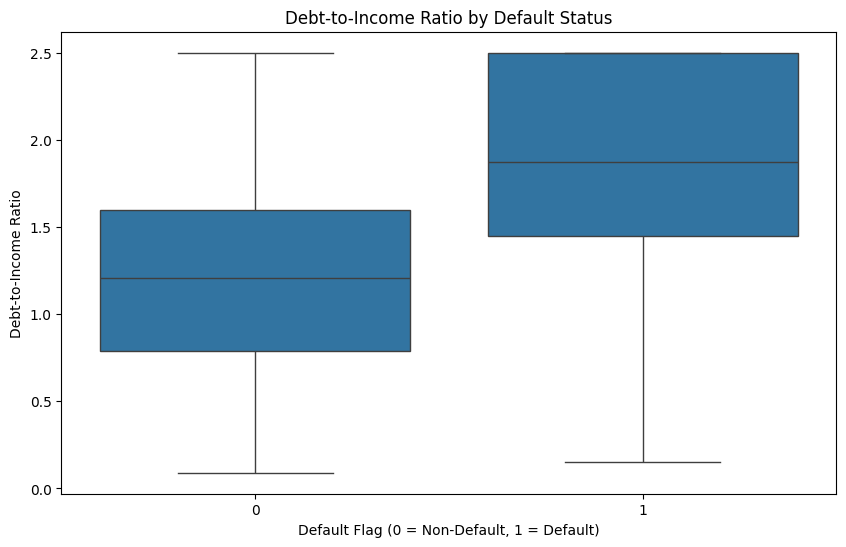

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="default_flag",
    y="debt_to_income_ratio"
)

plt.title("Debt-to-Income Ratio by Default Status")
plt.xlabel("Default Flag (0 = Non-Default, 1 = Default)")
plt.ylabel("Debt-to-Income Ratio")

plt.show()

In [14]:
# ============================================================
# 9. LOAN-TO-INCOME RATIO VS DEFAULT
# ============================================================

print("=" * 60)
print("LTI VS DEFAULT")
print("=" * 60)

lti_default = (
    df.groupby("default_flag")["loan_to_income_ratio"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)

lti_default

LTI VS DEFAULT


,count,mean,median,min,max
default_flag,,,,,
0,9300,1.598,1.110,0.05,15.0
1,700,3.121,2.365,0.07,15.0


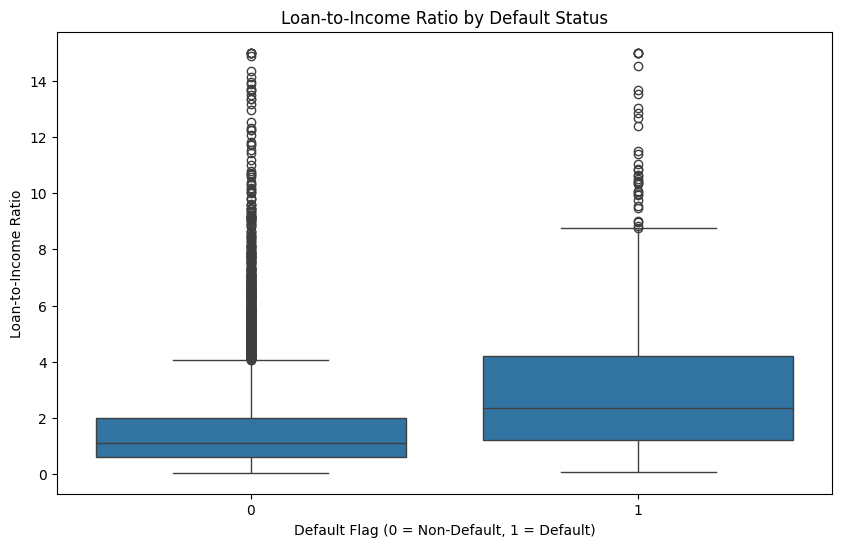

In [15]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="default_flag",
    y="loan_to_income_ratio"
)

plt.title("Loan-to-Income Ratio by Default Status")
plt.xlabel("Default Flag (0 = Non-Default, 1 = Default)")
plt.ylabel("Loan-to-Income Ratio")

plt.show()

In [16]:
# ============================================================
# 10. PREVIOUS DELINQUENCIES VS DEFAULT
# ============================================================

print("=" * 60)
print("PREVIOUS DELINQUENCIES VS DEFAULT")
print("=" * 60)

delinquency_default = (
    df.groupby("default_flag")["previous_delinquencies"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)

delinquency_default

PREVIOUS DELINQUENCIES VS DEFAULT


,count,mean,median,min,max
default_flag,,,,,
0,9300,0.338,0.0,0,4
1,700,0.660,0.0,0,4


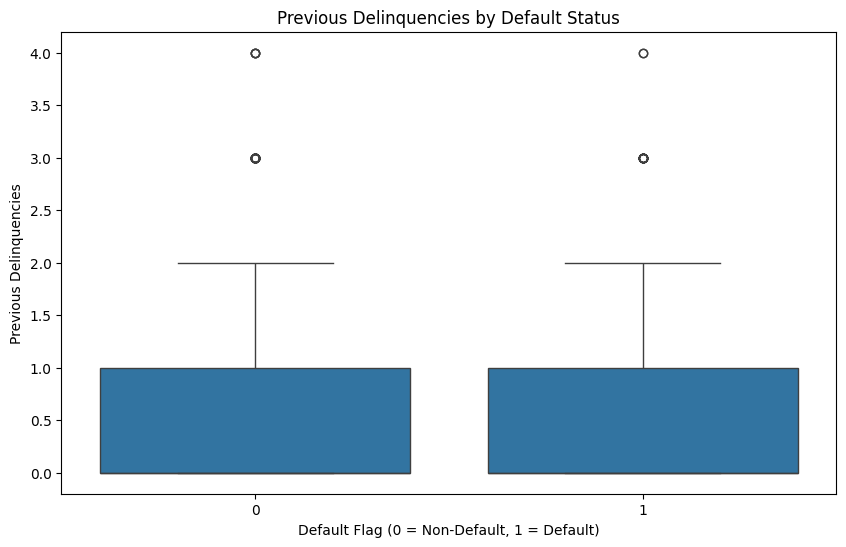

In [17]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="default_flag",
    y="previous_delinquencies"
)

plt.title("Previous Delinquencies by Default Status")
plt.xlabel("Default Flag (0 = Non-Default, 1 = Default)")
plt.ylabel("Previous Delinquencies")

plt.show()

In [18]:
# ============================================================
# 11. PREVIOUS DEFAULTS VS CURRENT DEFAULT
# ============================================================

print("=" * 60)
print("PREVIOUS DEFAULTS VS CURRENT DEFAULT")
print("=" * 60)

previous_default_analysis = pd.crosstab(
    df["previous_defaults"],
    df["default_flag"],
    normalize="index"
).mul(100).round(2)

previous_default_analysis.columns = [
    "Non_Default_Percentage",
    "Default_Percentage"
]

previous_default_analysis

PREVIOUS DEFAULTS VS CURRENT DEFAULT


,Non_Default_Percentage,Default_Percentage
previous_defaults,,
0,94.17,5.83
1,79.50,20.50


In [19]:

print("=" * 60)
print("LOAN AMOUNT VS DEFAULT")
print("=" * 60)

loan_default = (
    df.groupby("default_flag")["loan_amount"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

loan_default

LOAN AMOUNT VS DEFAULT


,count,mean,median,min,max
default_flag,,,,,
0,9300,853636.38,677453.5,51042.0,5000000.0
1,700,1335359.71,1078141.5,50000.0,5000000.0


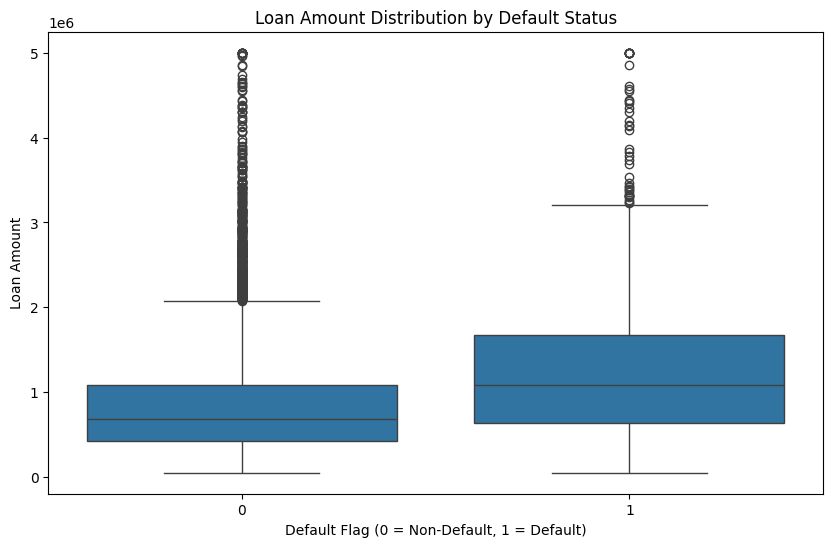

In [20]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="default_flag",
    y="loan_amount"
)

plt.title("Loan Amount Distribution by Default Status")
plt.xlabel("Default Flag (0 = Non-Default, 1 = Default)")
plt.ylabel("Loan Amount")

plt.show()

In [21]:
# ============================================================
# 13. INTEREST RATE VS DEFAULT
# ============================================================

print("=" * 60)
print("INTEREST RATE VS DEFAULT")
print("=" * 60)

interest_default = (
    df.groupby("default_flag")["interest_rate"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

interest_default

INTEREST RATE VS DEFAULT


,count,mean,median,min,max
default_flag,,,,,
0,9300,11.51,11.46,6.0,20.00
1,700,11.95,11.93,6.0,19.14


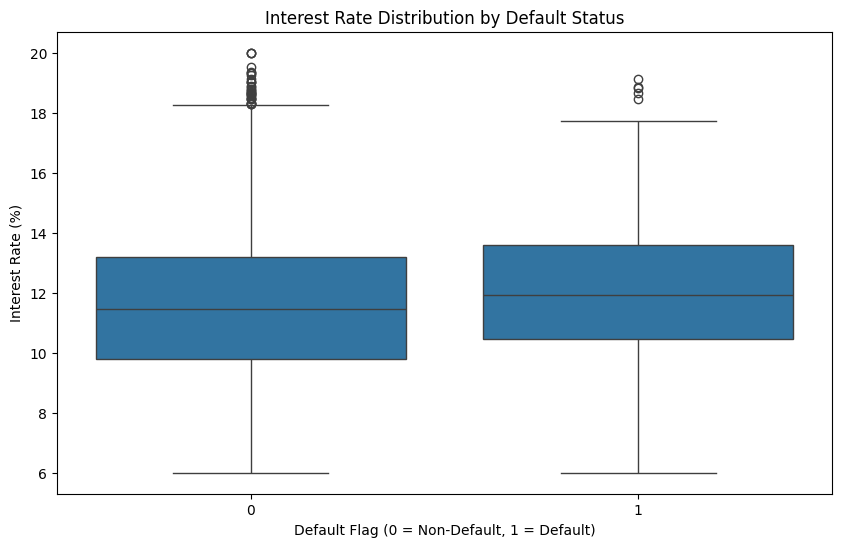

In [22]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="default_flag",
    y="interest_rate"
)

plt.title("Interest Rate Distribution by Default Status")
plt.xlabel("Default Flag (0 = Non-Default, 1 = Default)")
plt.ylabel("Interest Rate (%)")

plt.show()

In [23]:
# ============================================================
# 14. ANNUAL INCOME VS DEFAULT
# ============================================================

print("=" * 60)
print("ANNUAL INCOME VS DEFAULT")
print("=" * 60)

income_default = (
    df.groupby("default_flag")["annual_income"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

income_default

ANNUAL INCOME VS DEFAULT


,count,mean,median,min,max
default_flag,,,,,
0,9300,704498.79,613093.5,180000.0,4237196.0
1,700,570047.19,483414.5,180000.0,3613931.0


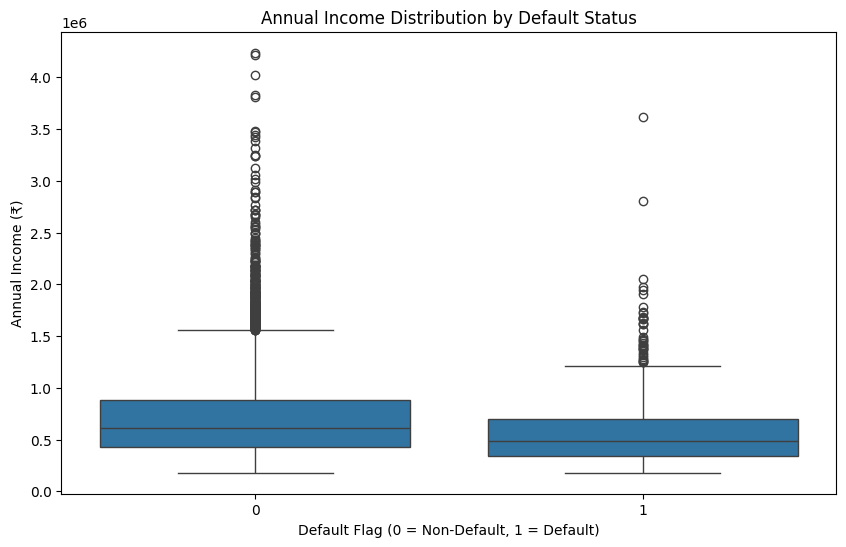

In [24]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="default_flag",
    y="annual_income"
)

plt.title("Annual Income Distribution by Default Status")
plt.xlabel("Default Flag (0 = Non-Default, 1 = Default)")
plt.ylabel("Annual Income (₹)")

plt.show()

In [25]:
# ============================================================
# 15. BANK-WISE DEFAULT RATE
# ============================================================

print("=" * 60)
print("BANK-WISE DEFAULT RATE")
print("=" * 60)

bank_default_rate = (
    df.groupby("bank")["default_flag"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "borrowers",
        "sum": "defaults",
        "mean": "default_rate"
    })
)

bank_default_rate["default_rate"] = (
    bank_default_rate["default_rate"] * 100
).round(2)

bank_default_rate = bank_default_rate.sort_values(
    "default_rate",
    ascending=False
)

bank_default_rate

BANK-WISE DEFAULT RATE


,borrowers,defaults,default_rate
bank,,,
NAINITAL BANK LTD,171,25,14.62
PUNJAB NATIONAL BANK,588,53,9.01
UCO BANK,243,21,8.64
AXIS BANK LIMITED,872,70,8.03
BANK OF MAHARASHTRA,304,23,7.57
BANDHAN BANK LIMITED,243,18,7.41
BANK OF BARODA,693,50,7.22
BANK OF INDIA,413,29,7.02
CANARA BANK,670,47,7.01


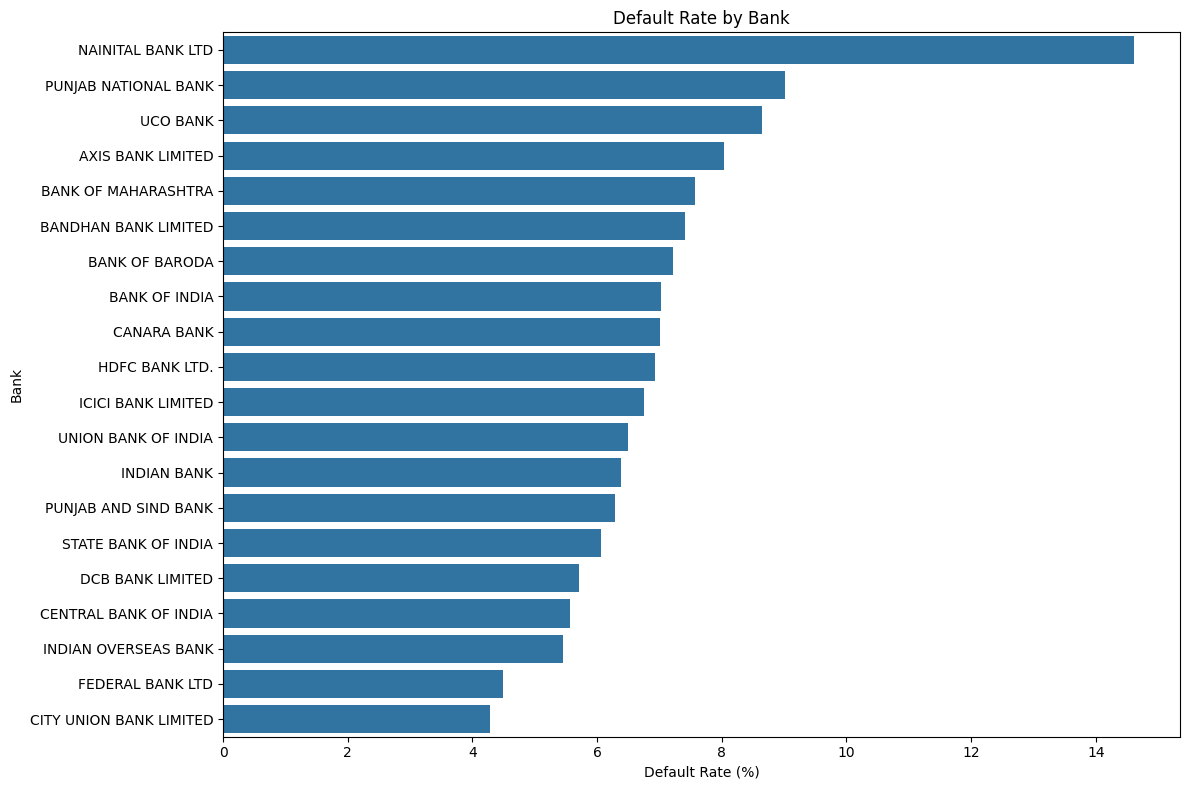

In [26]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=bank_default_rate.reset_index(),
    x="default_rate",
    y="bank"
)

plt.title("Default Rate by Bank")
plt.xlabel("Default Rate (%)")
plt.ylabel("Bank")

plt.tight_layout()
plt.show()

In [27]:
# ============================================================
# 16. RBI NPA RATIO VS BORROWER DEFAULT
# ============================================================

print("=" * 60)
print("RBI NPA RATIO VS BORROWER DEFAULT")
print("=" * 60)

npa_default = (
    df.groupby("default_flag")["bank_gross_npa_ratio"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)

npa_default

RBI NPA RATIO VS BORROWER DEFAULT


,count,mean,median,min,max
default_flag,,,,,
0,9300,2.428,1.84,1.33,7.78
1,700,2.555,2.14,1.33,7.78


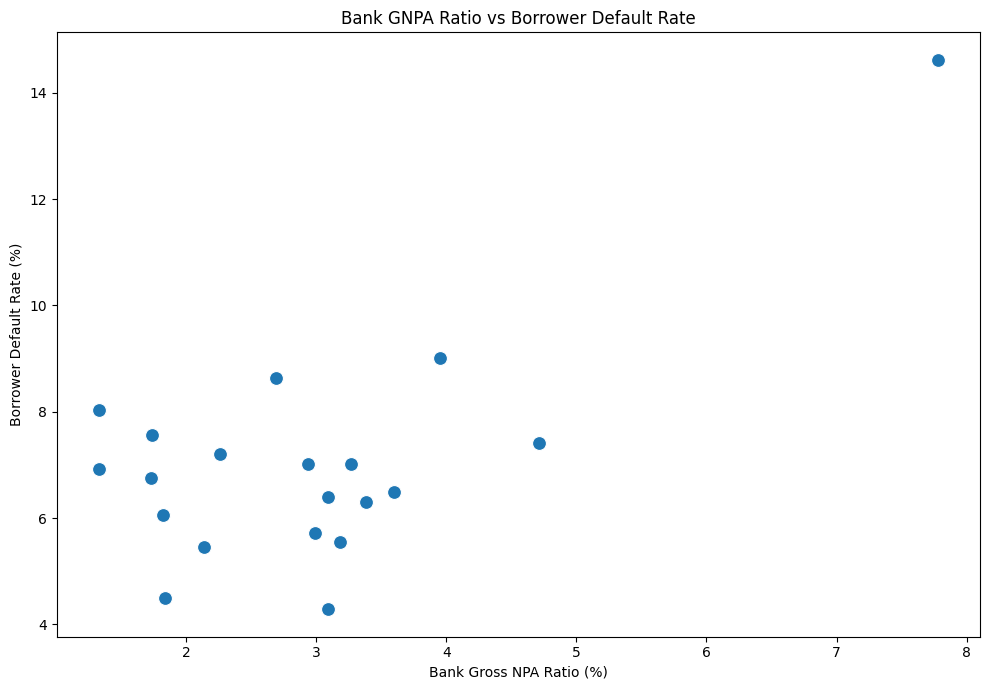

In [28]:
bank_npa_analysis = (
    df.groupby("bank")
    .agg(
        borrowers=("borrower_id", "count"),
        default_rate=("default_flag", "mean"),
        bank_npa_ratio=("bank_gross_npa_ratio", "first")
    )
    .reset_index()
)

bank_npa_analysis["default_rate"] = (
    bank_npa_analysis["default_rate"] * 100
)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=bank_npa_analysis,
    x="bank_npa_ratio",
    y="default_rate",
    s=100
)

plt.title("Bank GNPA Ratio vs Borrower Default Rate")
plt.xlabel("Bank Gross NPA Ratio (%)")
plt.ylabel("Borrower Default Rate (%)")

plt.tight_layout()
plt.show()

In [29]:
# ============================================================
# 17. RISK CATEGORY ANALYSIS
# ============================================================

print("=" * 60)
print("RISK CATEGORY ANALYSIS")
print("=" * 60)

risk_analysis = (
    df.groupby("risk_category", observed=False)
    .agg(
        borrowers=("borrower_id", "count"),
        defaults=("default_flag", "sum"),
        default_rate=("default_flag", "mean")
    )
)

risk_analysis["default_rate"] = (
    risk_analysis["default_rate"] * 100
).round(2)

risk_analysis

RISK CATEGORY ANALYSIS


,borrowers,defaults,default_rate
risk_category,,,
High,1500,444,29.60
Low,5000,0,0.00
Medium,3000,73,2.43
Very High,500,183,36.60


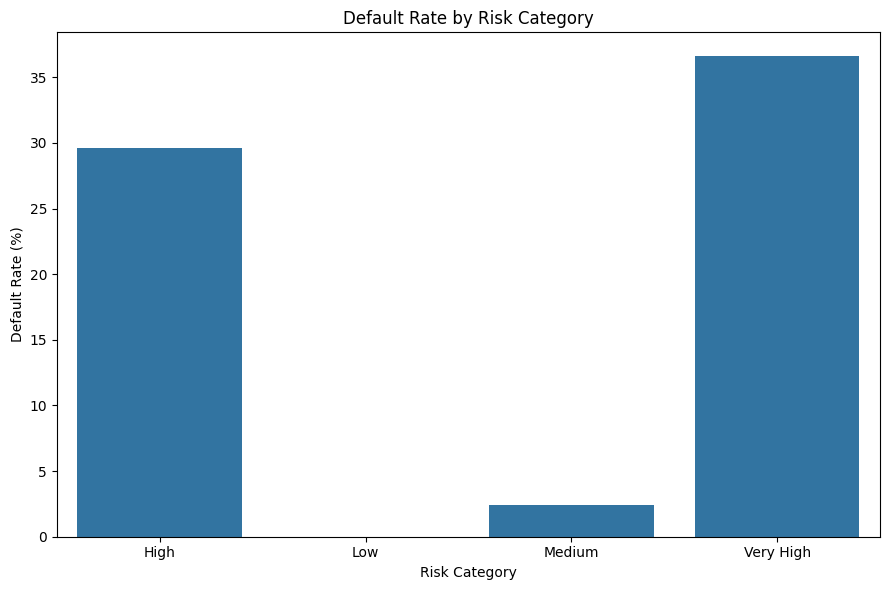

In [30]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=risk_analysis.reset_index(),
    x="risk_category",
    y="default_rate"
)

plt.title("Default Rate by Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

In [31]:
# ============================================================
# 18. CORRELATION ANALYSIS
# ============================================================

print("=" * 60)
print("CORRELATION ANALYSIS")
print("=" * 60)

correlation_matrix = df.select_dtypes(
    include=["int64", "float64"]
).corr()

correlation_matrix.round(2)

CORRELATION ANALYSIS


,age,employment_length_years,annual_income,credit_score,loan_amount,loan_term_months,interest_rate,existing_debt,existing_loans,previous_delinquencies,...,open_credit_accounts,dependents,monthly_income,monthly_emi,debt_to_income_ratio,loan_to_income_ratio,bank_gross_npas,bank_gross_advances,bank_gross_npa_ratio,default_flag
age,1.00,0.00,0.02,-0.00,-0.01,0.01,-0.01,0.02,0.01,-0.01,...,0.00,0.00,0.02,-0.01,-0.01,-0.02,0.01,0.01,-0.01,-0.00
employment_length_years,0.00,1.00,0.01,-0.00,0.01,0.01,-0.01,0.01,0.01,-0.01,...,0.02,-0.00,0.01,0.00,-0.01,-0.00,0.02,0.02,-0.03,-0.02
annual_income,0.02,0.01,1.00,0.01,-0.02,-0.01,0.00,0.68,0.01,-0.00,...,-0.00,0.00,1.00,-0.01,-0.31,-0.43,-0.00,-0.00,-0.00,-0.09
credit_score,-0.00,-0.00,0.01,1.00,-0.00,-0.00,-0.01,0.00,-0.02,0.00,...,-0.01,-0.02,0.01,-0.01,-0.00,0.00,-0.01,-0.01,-0.01,-0.20
loan_amount,-0.01,0.01,-0.02,-0.00,1.00,-0.01,-0.01,-0.02,0.00,0.01,...,-0.01,-0.01,-0.02,0.72,0.48,0.75,0.00,-0.00,0.01,0.18
loan_term_months,0.01,0.01,-0.01,-0.00,-0.01,1.00,-0.01,-0.01,-0.01,0.01,...,-0.01,0.01,-0.01,-0.41,-0.29,-0.00,-0.01,-0.01,-0.00,-0.08
interest_rate,-0.01,-0.01,0.00,-0.01,-0.01,-0.01,1.00,-0.00,-0.01,0.00,...,-0.00,0.01,0.00,0.03,0.03,-0.01,0.01,0.00,-0.00,0.05
existing_debt,0.02,0.01,0.68,0.00,-0.02,-0.01,-0.00,1.00,0.00,0.00,...,-0.01,-0.00,0.68,-0.01,0.21,-0.29,-0.00,0.00,-0.00,0.00
existing_loans,0.01,0.01,0.01,-0.02,0.00,-0.01,-0.01,0.00,1.00,-0.01,...,0.01,0.00,0.01,0.00,-0.01,-0.01,-0.01,-0.02,0.02,0.01
previous_delinquencies,-0.01,-0.01,-0.00,0.00,0.01,0.01,0.00,0.00,-0.01,1.00,...,-0.00,-0.02,-0.00,0.00,0.00,0.01,0.02,0.01,0.02,0.14


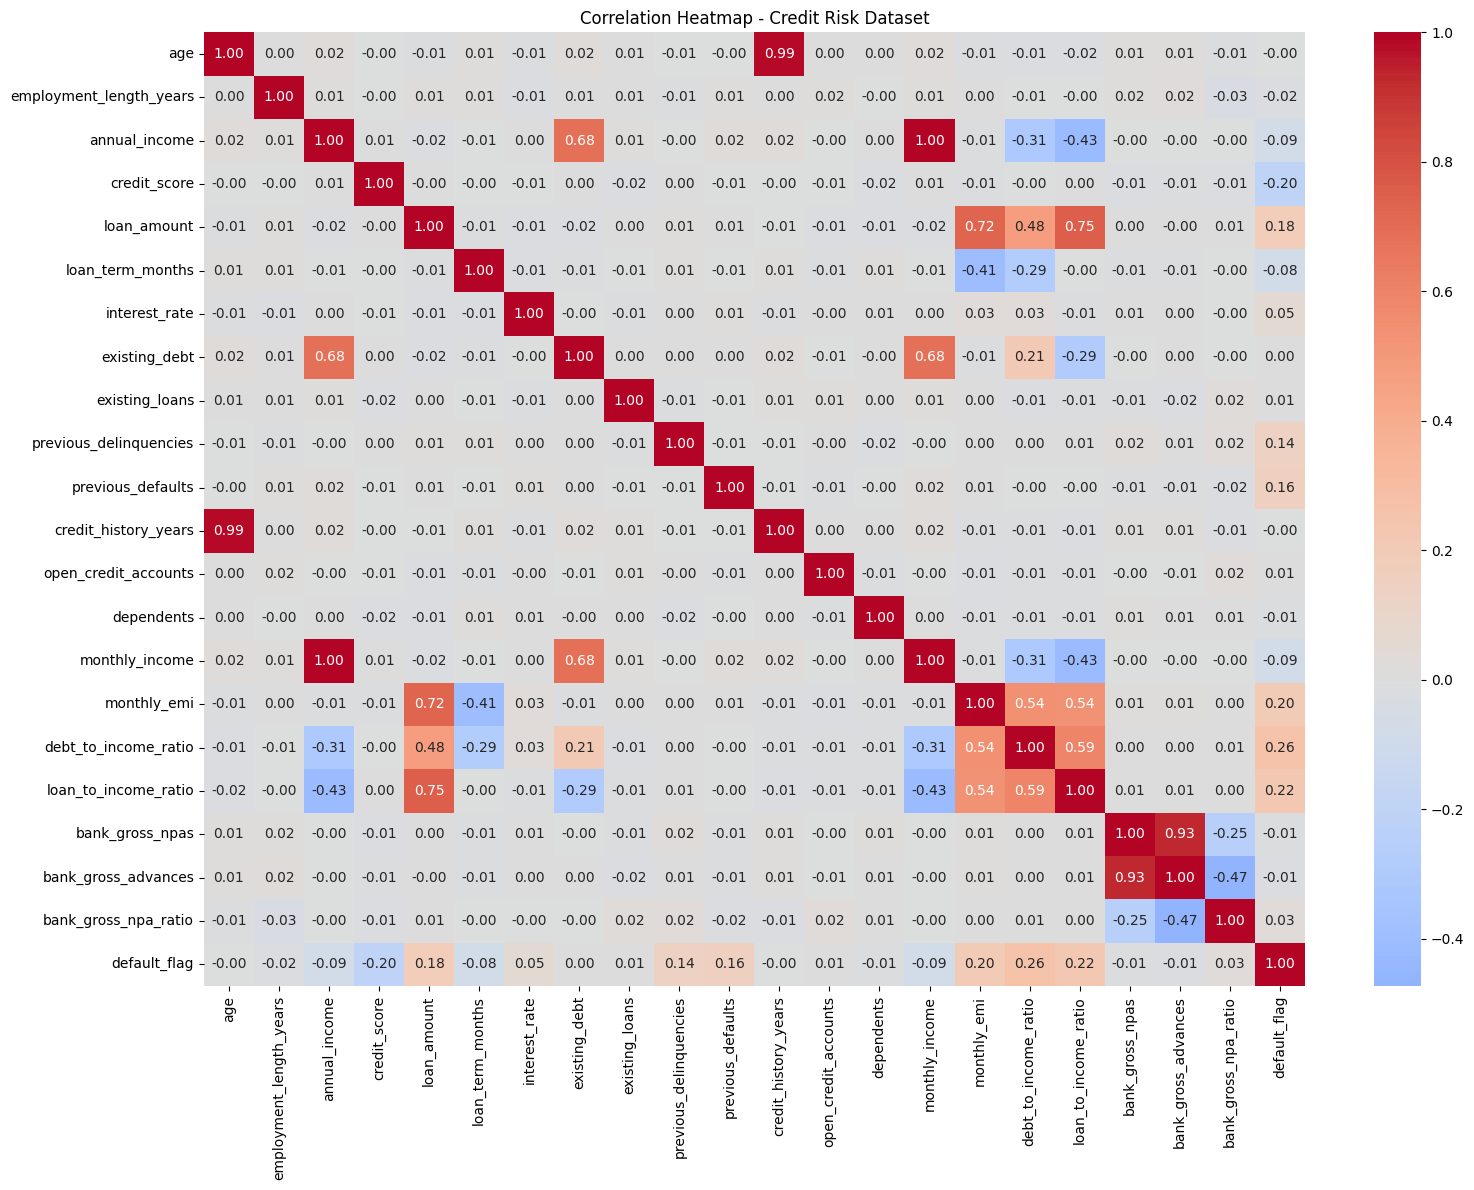

In [32]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap - Credit Risk Dataset")

plt.tight_layout()
plt.show()

In [33]:
# ============================================================
# 19. CREDIT SCORE BAND ANALYSIS
# ============================================================

df["credit_score_band"] = pd.cut(
    df["credit_score"],
    bins=[299, 579, 669, 739, 799, 900],
    labels=[
        "Poor (300-579)",
        "Fair (580-669)",
        "Good (670-739)",
        "Very Good (740-799)",
        "Excellent (800-900)"
]
)

credit_band_analysis = (
    df.groupby("credit_score_band", observed=False)
    .agg(
        borrowers=("borrower_id", "count"),
        defaults=("default_flag", "sum"),
        default_rate=("default_flag", "mean")
    )
)

credit_band_analysis["default_rate"] = (
    credit_band_analysis["default_rate"] * 100
).round(2)

credit_band_analysis

,borrowers,defaults,default_rate
credit_score_band,,,
Poor (300-579),339,91,26.84
Fair (580-669),2513,304,12.10
Good (670-739),3882,233,6.00
Very Good (740-799),2285,60,2.63
Excellent (800-900),981,12,1.22


In [34]:
# ============================================================
# 20. DTI BAND ANALYSIS
# ============================================================

df["dti_band"] = pd.cut(
    df["debt_to_income_ratio"],
    bins=[0, 0.50, 1.00, 1.50, 2.00, 2.50],
    labels=[
        "<= 0.50",
        "0.51 - 1.00",
        "1.01 - 1.50",
        "1.51 - 2.00",
        "2.01 - 2.50"
    ],
    include_lowest=True
)

dti_analysis = (
    df.groupby("dti_band", observed=False)
    .agg(
        borrowers=("borrower_id", "count"),
        defaults=("default_flag", "sum"),
        default_rate=("default_flag", "mean")
    )
)

dti_analysis["default_rate"] = (
    dti_analysis["default_rate"] * 100
).round(2)

dti_analysis

,borrowers,defaults,default_rate
dti_band,,,
<= 0.50,1005,8,0.80
0.51 - 1.00,2516,49,1.95
1.01 - 1.50,3126,141,4.51
1.51 - 2.00,2053,203,9.89
2.01 - 2.50,1300,299,23.00


# EDA Summary

## Key Questions Investigated

1. How is the default class distributed?
2. Does credit score differ between default and non-default borrowers?
3. How does debt burden affect default risk?
4. Does loan-to-income ratio relate to default?
5. Do previous delinquencies/defaults indicate higher risk?
6. Does bank-level GNPA provide additional risk context?
7. How does default rate vary across banks?
8. How do project-defined risk categories relate to default?
9. Which numerical variables show meaningful relationships with default?

## Business Interpretation

The EDA findings will be used to guide feature engineering and model development.

Important relationships should be validated statistically during model training rather than assumed solely from visual patterns.

In [35]:
# ============================================================
# 21. EMPLOYMENT TYPE VS DEFAULT
# ============================================================

print("=" * 60)
print("EMPLOYMENT TYPE VS DEFAULT")
print("=" * 60)

employment_analysis = (
    df.groupby("employment_type")["default_flag"]
    .agg(
        borrowers="count",
        defaults="sum",
        default_rate="mean"
    )
)

employment_analysis["default_rate"] = (
    employment_analysis["default_rate"] * 100
).round(2)

employment_analysis = employment_analysis.sort_values(
    "default_rate",
    ascending=False
)

employment_analysis

EMPLOYMENT TYPE VS DEFAULT


,borrowers,defaults,default_rate
employment_type,,,
Contract,1044,79,7.57
Self-Employed,2041,151,7.40
Business Owner,1491,106,7.11
Salaried,5424,364,6.71


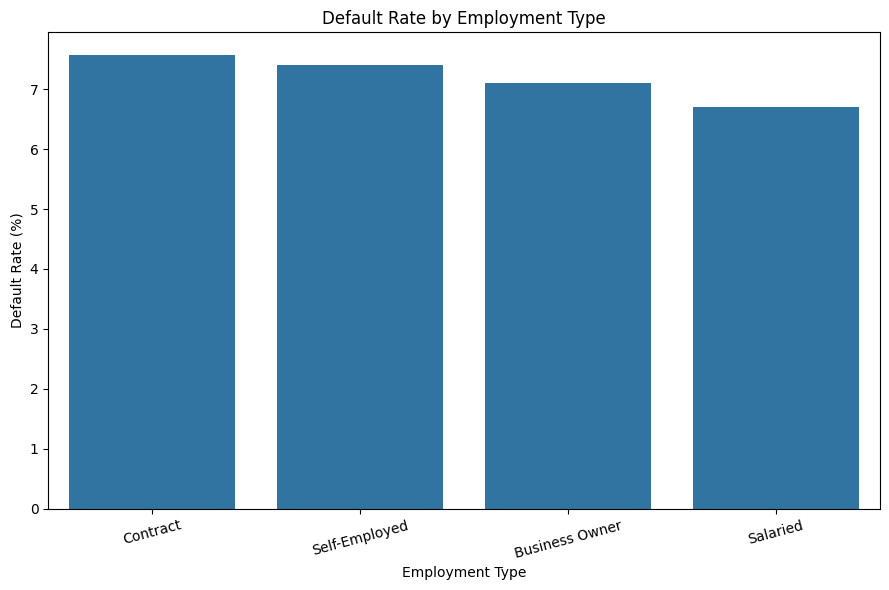

In [36]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=employment_analysis.reset_index(),
    x="employment_type",
    y="default_rate"
)

plt.title("Default Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Default Rate (%)")

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [37]:
# ============================================================
# 22. LOAN PURPOSE VS DEFAULT
# ============================================================

print("=" * 60)
print("LOAN PURPOSE VS DEFAULT")
print("=" * 60)

purpose_analysis = (
    df.groupby("loan_purpose")["default_flag"]
    .agg(
        borrowers="count",
        defaults="sum",
        default_rate="mean"
    )
)

purpose_analysis["default_rate"] = (
    purpose_analysis["default_rate"] * 100
).round(2)

purpose_analysis = purpose_analysis.sort_values(
    "default_rate",
    ascending=False
)

purpose_analysis

LOAN PURPOSE VS DEFAULT


,borrowers,defaults,default_rate
loan_purpose,,,
Business,1683,131,7.78
Vehicle,2037,144,7.07
Personal,2504,174,6.95
Home,1996,137,6.86
Medical,827,54,6.53
Education,953,60,6.30


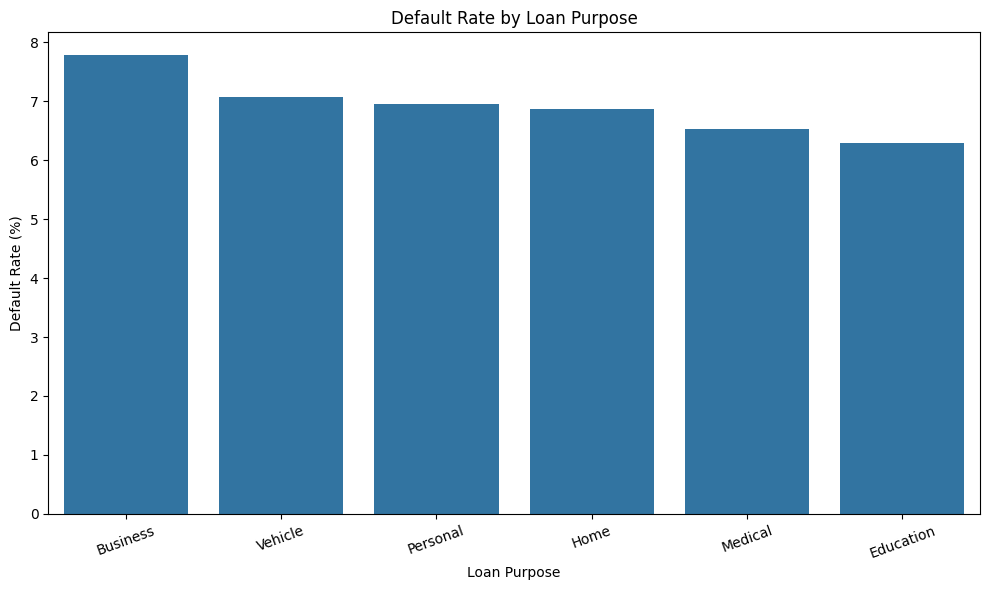

In [38]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=purpose_analysis.reset_index(),
    x="loan_purpose",
    y="default_rate"
)

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [39]:
# ============================================================
# 23. PREVIOUS DEFAULT IMPACT
# ============================================================

print("=" * 60)
print("PREVIOUS DEFAULT IMPACT")
print("=" * 60)

previous_default_analysis = (
    df.groupby("previous_defaults")["default_flag"]
    .agg(
        borrowers="count",
        defaults="sum",
        default_rate="mean"
    )
)

previous_default_analysis["default_rate"] = (
    previous_default_analysis["default_rate"] * 100
).round(2)

previous_default_analysis

PREVIOUS DEFAULT IMPACT


,borrowers,defaults,default_rate
previous_defaults,,,
0,9200,536,5.83
1,800,164,20.50


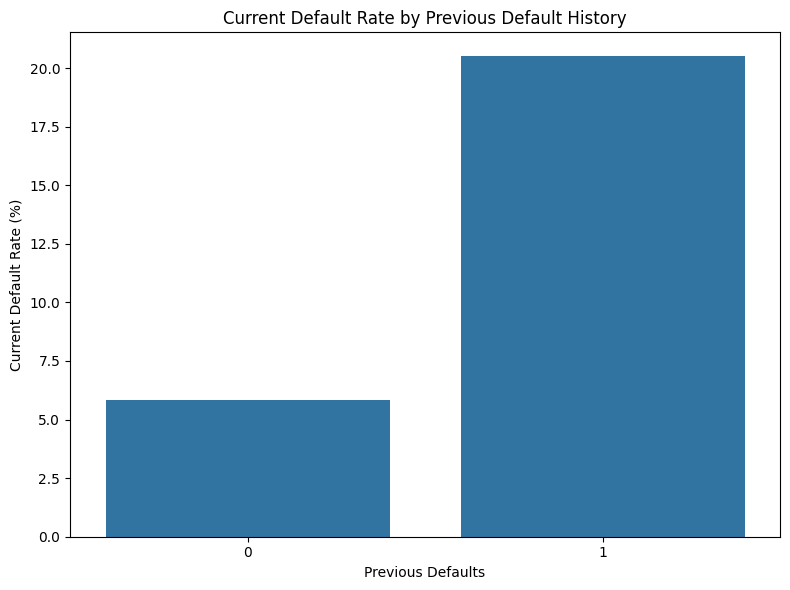

In [40]:
plt.figure(figsize=(8, 6))

sns.barplot(
    data=previous_default_analysis.reset_index(),
    x="previous_defaults",
    y="default_rate"
)

plt.title("Current Default Rate by Previous Default History")
plt.xlabel("Previous Defaults")
plt.ylabel("Current Default Rate (%)")

plt.tight_layout()
plt.show()

In [41]:
# ============================================================
# 24. OUTLIER DETECTION
# ============================================================

print("=" * 60)
print("OUTLIER DETECTION")
print("=" * 60)

outlier_columns = [
    "annual_income",
    "credit_score",
    "loan_amount",
    "interest_rate",
    "existing_debt",
    "monthly_emi",
    "debt_to_income_ratio",
    "loan_to_income_ratio"
]

outlier_summary = []

for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_summary.append({
        "feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": len(outliers),
        "outlier_percentage": (
            len(outliers) / len(df) * 100
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary["outlier_percentage"] = (
    outlier_summary["outlier_percentage"]
    .round(2)
)

outlier_summary

OUTLIER DETECTION


,feature,Q1,Q3,lower_bound,upper_bound,outlier_count,outlier_percentage
0,annual_income,416251.2500,8.662820e+05,-258794.87500,1.541328e+06,398,3.98
1,credit_score,662.0000,7.550000e+02,522.50000,8.945000e+02,88,0.88
2,loan_amount,434931.7500,1.123676e+06,-598185.00000,2.156793e+06,531,5.31
3,interest_rate,9.8400,1.322000e+01,4.77000,1.829000e+01,36,0.36
4,existing_debt,215550.0000,7.298598e+05,-555914.62500,1.501324e+06,397,3.97
5,monthly_emi,9860.0975,3.035421e+04,-20881.07500,6.109539e+04,688,6.88
6,debt_to_income_ratio,0.8200,1.650000e+00,-0.42500,2.895000e+00,0,0.00
7,loan_to_income_ratio,0.6400,2.122500e+00,-1.58375,4.346250e+00,689,6.89


In [42]:
# ============================================================
# 25. CORRELATION WITH DEFAULT FLAG
# ============================================================

print("=" * 60)
print("FEATURE CORRELATION WITH DEFAULT")
print("=" * 60)

correlation_with_default = (
    df.select_dtypes(include=["int64", "float64"])
    .corr()["default_flag"]
    .drop("default_flag")
    .sort_values(key=abs, ascending=False)
)

correlation_with_default

FEATURE CORRELATION WITH DEFAULT


debt_to_income_ratio       0.260722
loan_to_income_ratio       0.223963
credit_score              -0.204862
monthly_emi                0.198472
loan_amount                0.181059
previous_defaults          0.156025
previous_delinquencies     0.136290
annual_income             -0.085196
monthly_income            -0.085196
loan_term_months          -0.078387
interest_rate              0.045813
bank_gross_npa_ratio       0.028545
employment_length_years   -0.016797
bank_gross_advances       -0.014667
bank_gross_npas           -0.012388
dependents                -0.010286
existing_loans             0.008713
open_credit_accounts       0.006410
existing_debt              0.002303
age                       -0.002019
credit_history_years      -0.001997
Name: default_flag, dtype: float64

# EDA Summary

## Dataset Overview

- Total borrowers: 10,000
- Default cases: 700
- Non-default cases: 9,300
- Default rate: 7%
- Banks represented: 20
- Total original features: 28

## Analysis Performed

- Target class distribution
- Numerical feature statistics
- Categorical feature distributions
- Credit score vs default
- Debt-to-income ratio vs default
- Loan-to-income ratio vs default
- Loan amount vs default
- Interest rate vs default
- Income vs default
- Previous delinquency analysis
- Previous default history analysis
- Bank-wise default rate
- RBI bank GNPA ratio analysis
- Risk category analysis
- Credit score band analysis
- DTI band analysis
- Employment type analysis
- Loan purpose analysis
- Outlier detection
- Correlation analysis

## Key Findings

The observations from this notebook will be used to guide feature engineering and model development.

Relationships observed during EDA should be validated through machine-learning models and appropriate evaluation metrics.

## Important Modeling Considerations

1. The dataset contains a 7% minority default class.
2. Train/test splitting must be performed before applying SMOTE.
3. SMOTE must be applied only to the training data.
4. Test data must remain untouched.
5. `default_flag` is the target variable.
6. `borrower_id` should not be used as a model feature.
7. `risk_category` should not be used as a model feature because it is a project-derived risk segmentation.
8. EDA-only variables such as `credit_score_band` and `dti_band` should not automatically be treated as final model features.

In [43]:
# ============================================================
# 27. EDA CLEANUP
# ============================================================

eda_only_columns = [
    "credit_score_band",
    "dti_band"
]

df_eda = df.drop(
    columns=eda_only_columns,
    errors="ignore"
).copy()

print("=" * 60)
print("EDA COMPLETED")
print("=" * 60)

print("\nOriginal Dataset:")
print("Rows:", len(df))
print("Columns before EDA-only cleanup:", len(df.columns))

print("\nClean EDA Dataset:")
print("Rows:", len(df_eda))
print("Columns:", len(df_eda.columns))

print("\nEDA-only columns removed:")
print(eda_only_columns)

print("\nNo CSV has been overwritten.")

EDA COMPLETED

Original Dataset:
Rows: 10000
Columns before EDA-only cleanup: 30

Clean EDA Dataset:
Rows: 10000
Columns: 28

EDA-only columns removed:
['credit_score_band', 'dti_band']

No CSV has been overwritten.
